
# GDP Analysis: 2000–2022

## D100 Fundamentals of Data Science — Exercise 2

This notebook analyses annual real GDP for seven countries:

- United Kingdom
- United States
- Brazil
- Japan
- China
- Germany
- Switzerland

Data source: World Bank.

GDP is measured in constant US dollars.

The analysis demonstrates a modular Python workflow
for data loading, cleaning, and visualisation.


In [1]:

from gdp_analysis.data_loader import load_gdp_data
from gdp_analysis.data_cleaning import clean_gdp_data
from gdp_analysis.plotting import plot_gdp

import matplotlib.pyplot as plt


In [2]:
raw_data = load_gdp_data()

print("Raw data shape:", raw_data.shape)

raw_data.head()

Raw data shape: (161, 8)


,indicator,country,countryiso3code,date,value,unit,obs_status,decimal
0,"{'id': 'NY.GDP.MKTP.KD', 'value': 'GDP (consta...","{'id': 'BR', 'value': 'Brazil'}",BRA,2022,1.899505e+12,,,0
1,"{'id': 'NY.GDP.MKTP.KD', 'value': 'GDP (consta...","{'id': 'BR', 'value': 'Brazil'}",BRA,2021,1.843881e+12,,,0
2,"{'id': 'NY.GDP.MKTP.KD', 'value': 'GDP (consta...","{'id': 'BR', 'value': 'Brazil'}",BRA,2020,1.760057e+12,,,0
3,"{'id': 'NY.GDP.MKTP.KD', 'value': 'GDP (consta...","{'id': 'BR', 'value': 'Brazil'}",BRA,2019,1.819683e+12,,,0
4,"{'id': 'NY.GDP.MKTP.KD', 'value': 'GDP (consta...","{'id': 'BR', 'value': 'Brazil'}",BRA,2018,1.797737e+12,,,0


In [3]:
clean_data = clean_gdp_data(raw_data)

print("Cleaned data shape:", clean_data.shape)

clean_data.head()

Cleaned data shape: (161, 3)


,country,year,gdp
0,Brazil,2000,1.186419e+12
1,Brazil,2001,1.202909e+12
2,Brazil,2002,1.239639e+12
3,Brazil,2003,1.253782e+12
4,Brazil,2004,1.325999e+12


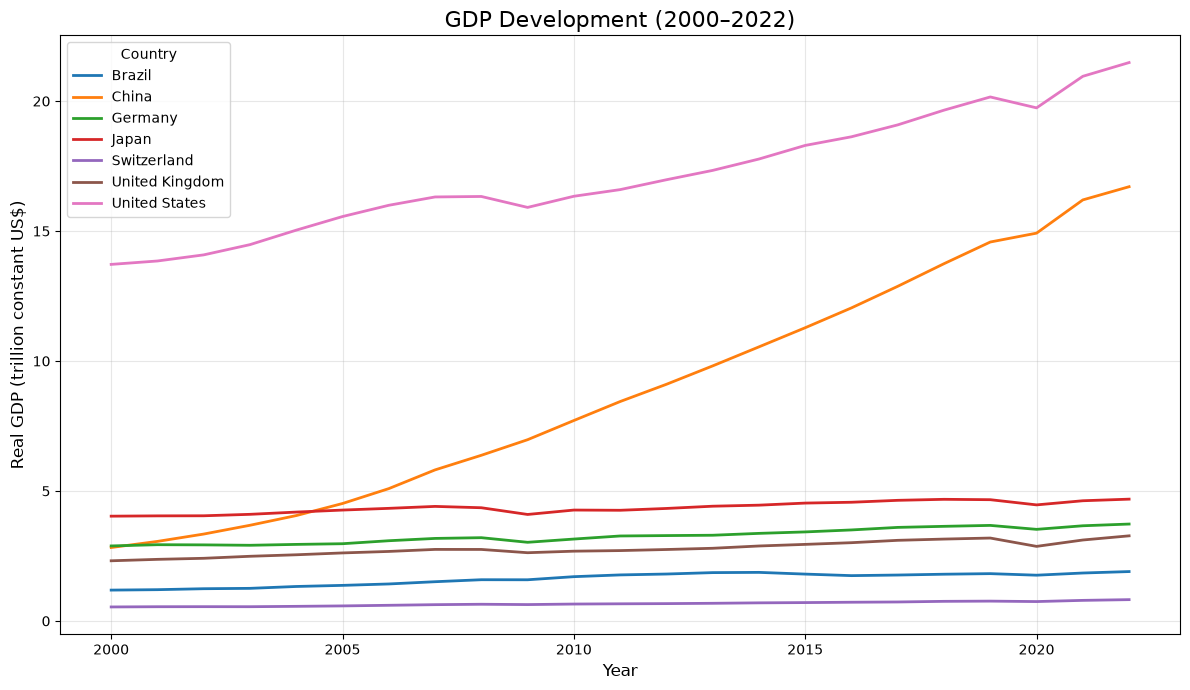

In [4]:
fig = plot_gdp(clean_data)

plt.show()

In [5]:
print("Countries:")
print(clean_data["country"].unique())

print("\nYear range:")
print(clean_data["year"].min(), "-", clean_data["year"].max())

Countries:
<StringArray>
[        'Brazil',          'China',        'Germany',          'Japan',
    'Switzerland', 'United Kingdom',  'United States']
Length: 7, dtype: str

Year range:
2000 - 2022


In [6]:
# Compare GDP in 2000 and 2022

gdp_comparison = clean_data[
    clean_data["year"].isin([2000, 2022])
]

gdp_comparison = gdp_comparison.pivot(
    index="country",
    columns="year",
    values="gdp"
)

# Calculate percentage change over the period
gdp_comparison["Growth (%)"] = (
    (gdp_comparison[2022] / gdp_comparison[2000] - 1)
    * 100
)

# Rename GDP columns and convert to trillions
gdp_comparison = gdp_comparison.rename(
    columns={
        2000: "GDP 2000",
        2022: "GDP 2022"
    }
)

gdp_comparison["GDP 2000"] /= 1e12
gdp_comparison["GDP 2022"] /= 1e12

gdp_comparison.round(2)

year,GDP 2000,GDP 2022,Growth (%)
country,,,
Brazil,1.19,1.90,60.10
China,2.82,16.71,491.40
Germany,2.89,3.73,29.17
Japan,4.03,4.69,16.24
Switzerland,0.54,0.82,52.21
United Kingdom,2.31,3.27,41.48
United States,13.72,21.48,56.61


## GDP Development: 2000–2022

The analysis reveals substantial differences in real GDP growth across the seven countries between 2000 and 2022.

- **China:** China experienced the strongest GDP growth, increasing by **491.40%**, from approximately $2.82 trillion to $16.71 trillion. This reflects China's rapid economic expansion over the period.

- **United States:** The United States maintained the highest GDP throughout the period, increasing by **56.61%**, from $13.72 trillion to $21.48 trillion.

- **Brazil:** Brazil's GDP increased by **60.10%**, although its development was uneven, with periods of economic expansion and contraction.

- **Japan:** Japan recorded the slowest GDP growth among the seven countries, increasing by only **16.24%**, consistent with its comparatively prolonged economic stagnation.

- **Germany:** Germany's GDP increased by **29.17%**, from $2.89 trillion to $3.73 trillion, indicating moderate long-term economic growth.

- **United Kingdom:** The UK's GDP increased by **41.48%**, from $2.31 trillion to $3.27 trillion, despite periods of economic disruption.

- **Switzerland:** Switzerland experienced **52.21%** GDP growth, from approximately $0.54 trillion to $0.82 trillion.

### Overall conclusion

All seven economies experienced positive cumulative real GDP growth between 2000 and 2022, but at markedly different rates.

China experienced by far the strongest expansion, while Japan recorded the slowest growth. The United States remained the largest economy in absolute GDP terms among the countries studied.

The GDP trajectories also illustrate how global events, including the 2008–2009 financial crisis and the COVID-19 pandemic, affected economic activity.

**Limitation:** The analysis compares total real GDP rather than GDP per capita. Therefore, higher GDP does not necessarily indicate higher individual income or living standards.